# Regressão linear: simples e multipla

Simples - uma variavel explicativa

Múltipla - N varivaies explicatitavas


Uma empresa está interessada em verificar

 se a
 remuneção dos seus colaboradores está de
 acordo com as politicas da empresa

 Para isso precisamos de uma amostra de 46 colaboradores.

 Pergunta de negócio: o salario muda de acordo com os anos de educação superior?

  Se o salario muda, é possivel construir um modelo que estime o salario de acordo com esses anos?



In [ ]:
#bibliotecas de manipulação
import pandas as pd
import numpy as np


# bibliotecas graficas
import matplotlib.pyplot as plt
import seaborn as sns

# bibliotecas de modelagem estatitica

import statsmodels.api as sm

In [ ]:
# carregando o arquivo
df = pd.read_csv('base_funcionarios_v2.csv', delimiter=';', index_col='id')
df.head()

,Salario,Anos_Educ_Superior,Tempo_Empresa
id,,,
1,5517.4,3,3
2,6399.9,4,6
3,6206.7,6,3
4,6060.6,4,5
5,6122.7,2,9


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 46 entries, 1 to 46
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Salario             46 non-null     float64
 1   Anos_Educ_Superior  46 non-null     int64  
 2   Tempo_Empresa       46 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 1.4 KB


In [ ]:
df.shape

(46, 3)

In [ ]:
df.describe().round(1)

,Salario,Anos_Educ_Superior,Tempo_Empresa
count,46.0,46.0,46.0
mean,6969.8,5.1,10.3
std,1924.9,2.8,7.6
min,4139.5,0.0,0.0
25%,5818.4,4.0,5.2
50%,6394.8,5.0,8.5
75%,7972.4,6.0,17.2
max,12118.1,12.0,27.0


<Axes: xlabel='Anos_Educ_Superior', ylabel='Salario'>

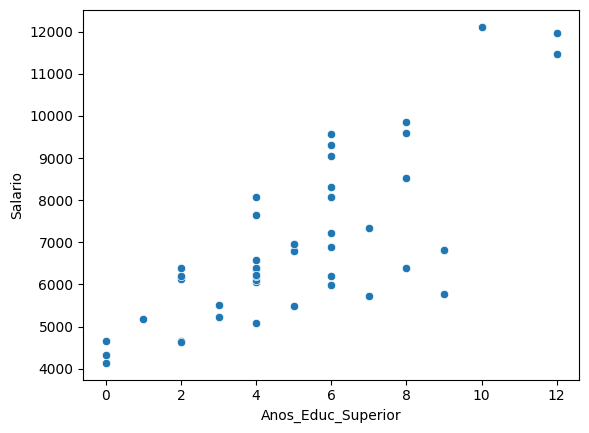

In [ ]:
# Grafico de dispersão

sns.scatterplot(x=df['Anos_Educ_Superior'], y=df['Salario'])
# salario é variavel resposta ou dependente
#anos_de_educação é variavel explicativa

<Axes: xlabel='Tempo_Empresa', ylabel='Salario'>

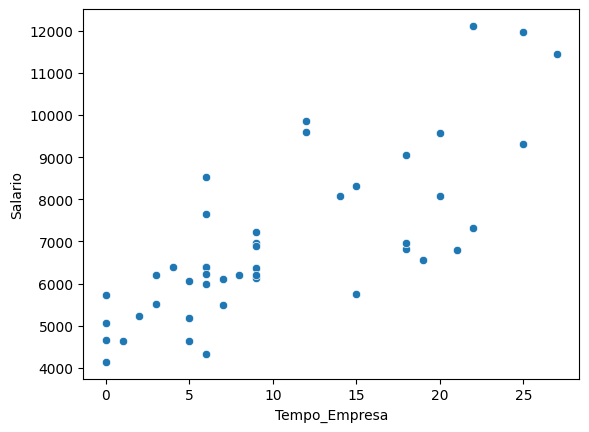

In [ ]:
sns.scatterplot(x=df['Tempo_Empresa'], y=df['Salario'])
# salario é variavel resposta ou dependente
#anos_de_educação é variavel explicativa

baseado no grafico de disperção existe uma correlação positiva - o que significa que os dados confirmam a corelação dos valores


In [ ]:
#corelação linear de pearson
df.corr()

,Salario,Anos_Educ_Superior,Tempo_Empresa
Salario,1.000000,0.776992,0.765173
Anos_Educ_Superior,0.776992,1.000000,0.607486
Tempo_Empresa,0.765173,0.607486,1.000000


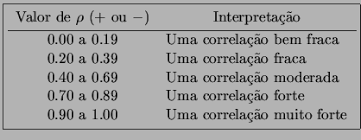

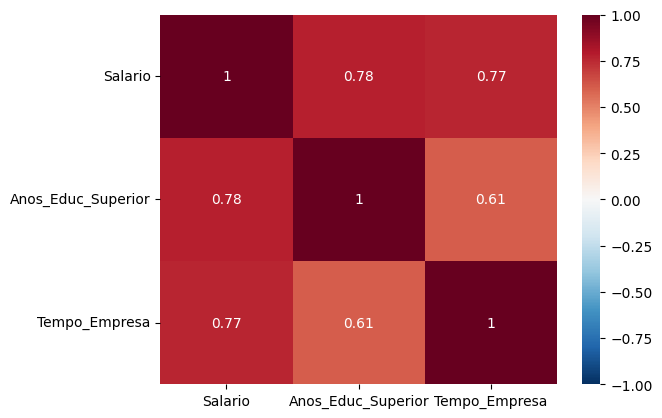

In [ ]:
# Gráfico heatMap
sns.heatmap(
    df.corr(),
    cmap='RdBu_r',
    vmin=-1, vmax=1,
    annot=True
);

## ajuste do modelo de regressao linear

In [ ]:
#Variavel Resposta
y= df['Salario']

# Variavel explicativa
df['intercepto'] = 1
x = df[['intercepto','Anos_Educ_Superior', 'Tempo_Empresa']]

In [ ]:
#ajuste do modelo de regressao linear
modelo = sm.OLS(y,x)
resultado = modelo.fit()

In [ ]:
# resultado do modelo
print(resultado.summary())

                            OLS Regression Results                            
Dep. Variable:                Salario   R-squared:                       0.740
Model:                            OLS   Adj. R-squared:                  0.728
Method:                 Least Squares   F-statistic:                     61.17
Date:                Sat, 08 Nov 2025   Prob (F-statistic):           2.66e-13
Time:                        15:44:30   Log-Likelihood:                -381.67
No. Observations:                  46   AIC:                             769.3
Df Residuals:                      43   BIC:                             774.8
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
intercepto          4056.0591    309

<Axes: xlabel='Anos_Educ_Superior', ylabel='Salario'>

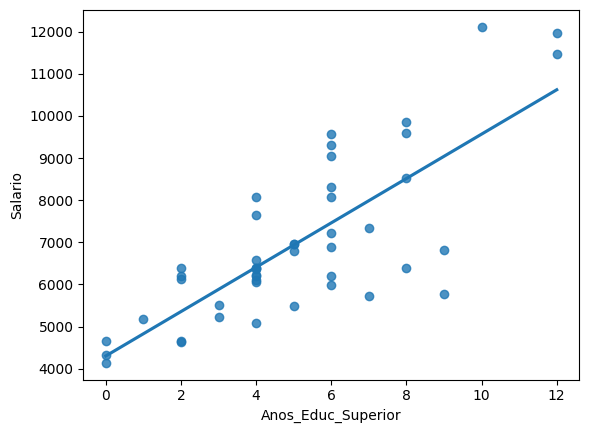

In [ ]:
# grafico de dispersão com regressao linear
sns.regplot(x=df['Anos_Educ_Superior'],y=df['Salario'], ci=False)

# Regressão Robusta

In [ ]:
# Criar o modelo de Regressão Robusta (RLM)

modelo_rlm = sm.RLM(y, x, M=sm.robust.norms.HuberT())
resultado_rlm = modelo_rlm.fit()

print(resultado_rlm.summary())

                    Robust linear Model Regression Results                    
Dep. Variable:                Salario   No. Observations:                   46
Model:                            RLM   Df Residuals:                       43
Method:                          IRLS   Df Model:                            2
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Sat, 08 Nov 2025                                         
Time:                        15:44:31                                         
No. Iterations:                    13                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
intercepto          3968.6282    227

In [ ]:
# comparar os coeficientes
comparacao = pd.DataFrame({
    'Coeficiente_OLS': resultado.params,
    'Coeficiente_RLM': resultado_rlm.params
})
print(comparacao)

                    Coeficiente_OLS  Coeficiente_RLM
intercepto              4056.059053      3968.628232
Anos_Educ_Superior       335.386768       326.220757
Tempo_Empresa            117.656562       139.547865


#  Regressão Quantílica

In [ ]:
import statsmodels.formula.api as smf
#Criar os modelos para diferentes quantis
# Para a Regressão Quantílica, usar a notação de fórmula é mais fácil
# A fórmula 'Salario ~ Anos_Educ_Superior + Tempo_Empresa' é um atalho
# para o que estávamos fazendo com X e y.

# Modelo para o quantil 0.25 (quartil inferior)
modelo_q25 = smf.quantreg('Salario ~ Anos_Educ_Superior + Tempo_Empresa', df)
resultado_q25 = modelo_q25.fit(q=0.25)

# Modelo para o quantil 0.50 (mediana)
modelo_q50 = smf.quantreg('Salario ~ Anos_Educ_Superior + Tempo_Empresa', df)
resultado_q50 = modelo_q50.fit(q=0.50)

# Modelo para o quantil 0.75 (quartil superior)
modelo_q75 = smf.quantreg('Salario ~ Anos_Educ_Superior + Tempo_Empresa', df)
resultado_q75 = modelo_q75.fit(q=0.75)


In [ ]:
# Comparar os resultados dos coeficientes

comparacao_quantis = pd.DataFrame({
    'Baixos Salários (q=0.25)': resultado_q25.params,
    'Salários na Mediana (q=0.50)': resultado_q50.params,
    'Altos Salários (q=0.75)': resultado_q75.params
})
print(comparacao_quantis)


                    Baixos Salários (q=0.25)  Salários na Mediana (q=0.50)  \
Intercept                        4139.500000                   4054.720548   
Anos_Educ_Superior                233.225003                    298.239726   
Tempo_Empresa                      92.459721                    141.726027   

                    Altos Salários (q=0.75)  
Intercept                       4071.245452  
Anos_Educ_Superior               360.381813  
Tempo_Empresa                    147.854547  
